Mount Drive & Install Library

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q pandas numpy scikit-learn matplotlib joblib
print(" Setup xong")

Mounted at /content/drive
 Setup xong


Load data Prometheus

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/content/drive/MyDrive/network-monitor/data/metrics_history.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

print(f" Loaded {len(df):,} records")
print(f"   Devices : {sorted(df['device'].unique())}")
print(f"   Sites   : {sorted(df['site'].unique())}")
print(f"   Metrics : {sorted(df['metric'].unique())}")
print(f"   From    : {df['timestamp'].min()}")
print(f"   To      : {df['timestamp'].max()}")
print(f"\nSample data:")
df.head(3)

 Loaded 8,925 records
   Devices : ['Core-Router', 'Server01', 'Server02', 'SwitchL3A', 'SwitchL3B']
   Sites   : ['Vy']
   Metrics : ['cpu_percent', 'disk_used_pct', 'in_errors', 'mem_used_pct', 'out_discards', 'out_errors', 'traffic_in_bps', 'traffic_out_bps']
   From    : 2026-04-12 20:25:49.615000
   To      : 2026-04-12 21:59:49.615000

Sample data:


,timestamp,device,site,type,interface,metric,value
0,2026-04-12 20:25:49.615,SwitchL3A,Vy,switch,GigabitEthernet0/1,out_discards,0.0
1,2026-04-12 20:25:49.615,Core-Router,Vy,router,Loopback0,out_discards,0.0
2,2026-04-12 20:25:49.615,SwitchL3B,Vy,switch,Loopback0,out_errors,0.0


Kiểm tra data quality

In [3]:
import matplotlib.pyplot as plt

# Thống kê từng metric
print("=== THỐNG KÊ TỪNG METRIC ===\n")
for metric in sorted(df['metric'].unique()):
    sub = df[df['metric'] == metric]['value']
    q99 = sub.quantile(0.99)
    print(f"{metric:25s} | count={len(sub):6,} | "
          f"mean={sub.mean():10.2f} | "
          f"p99={q99:12.2f} | "
          f"max={sub.max():12.2f}")

# Kiểm tra missing values
print(f"\nMissing values: {df['value'].isna().sum()}")
print(f"Infinity values: {np.isinf(df['value']).sum()}")

=== THỐNG KÊ TỪNG METRIC ===

cpu_percent               | count=   102 | mean=      2.95 | p99=       82.14 | max=       96.73
disk_used_pct             | count=    92 | mean=      2.63 | p99=        2.69 | max=        2.70
in_errors                 | count= 1,689 | mean=    281.21 | p99=     8399.56 | max=    10306.00
mem_used_pct              | count=    92 | mean=     15.81 | p99=       18.81 | max=       18.84
out_discards              | count= 1,689 | mean=      0.00 | p99=        0.00 | max=        0.00
out_errors                | count= 1,689 | mean=      0.00 | p99=        0.00 | max=        0.00
traffic_in_bps            | count= 1,786 | mean=    649.23 | p99=     4266.16 | max=     7493.33
traffic_out_bps           | count= 1,786 | mean=   1215.86 | p99=    11940.19 | max=    18755.20

Missing values: 0
Infinity values: 0


Visualize data

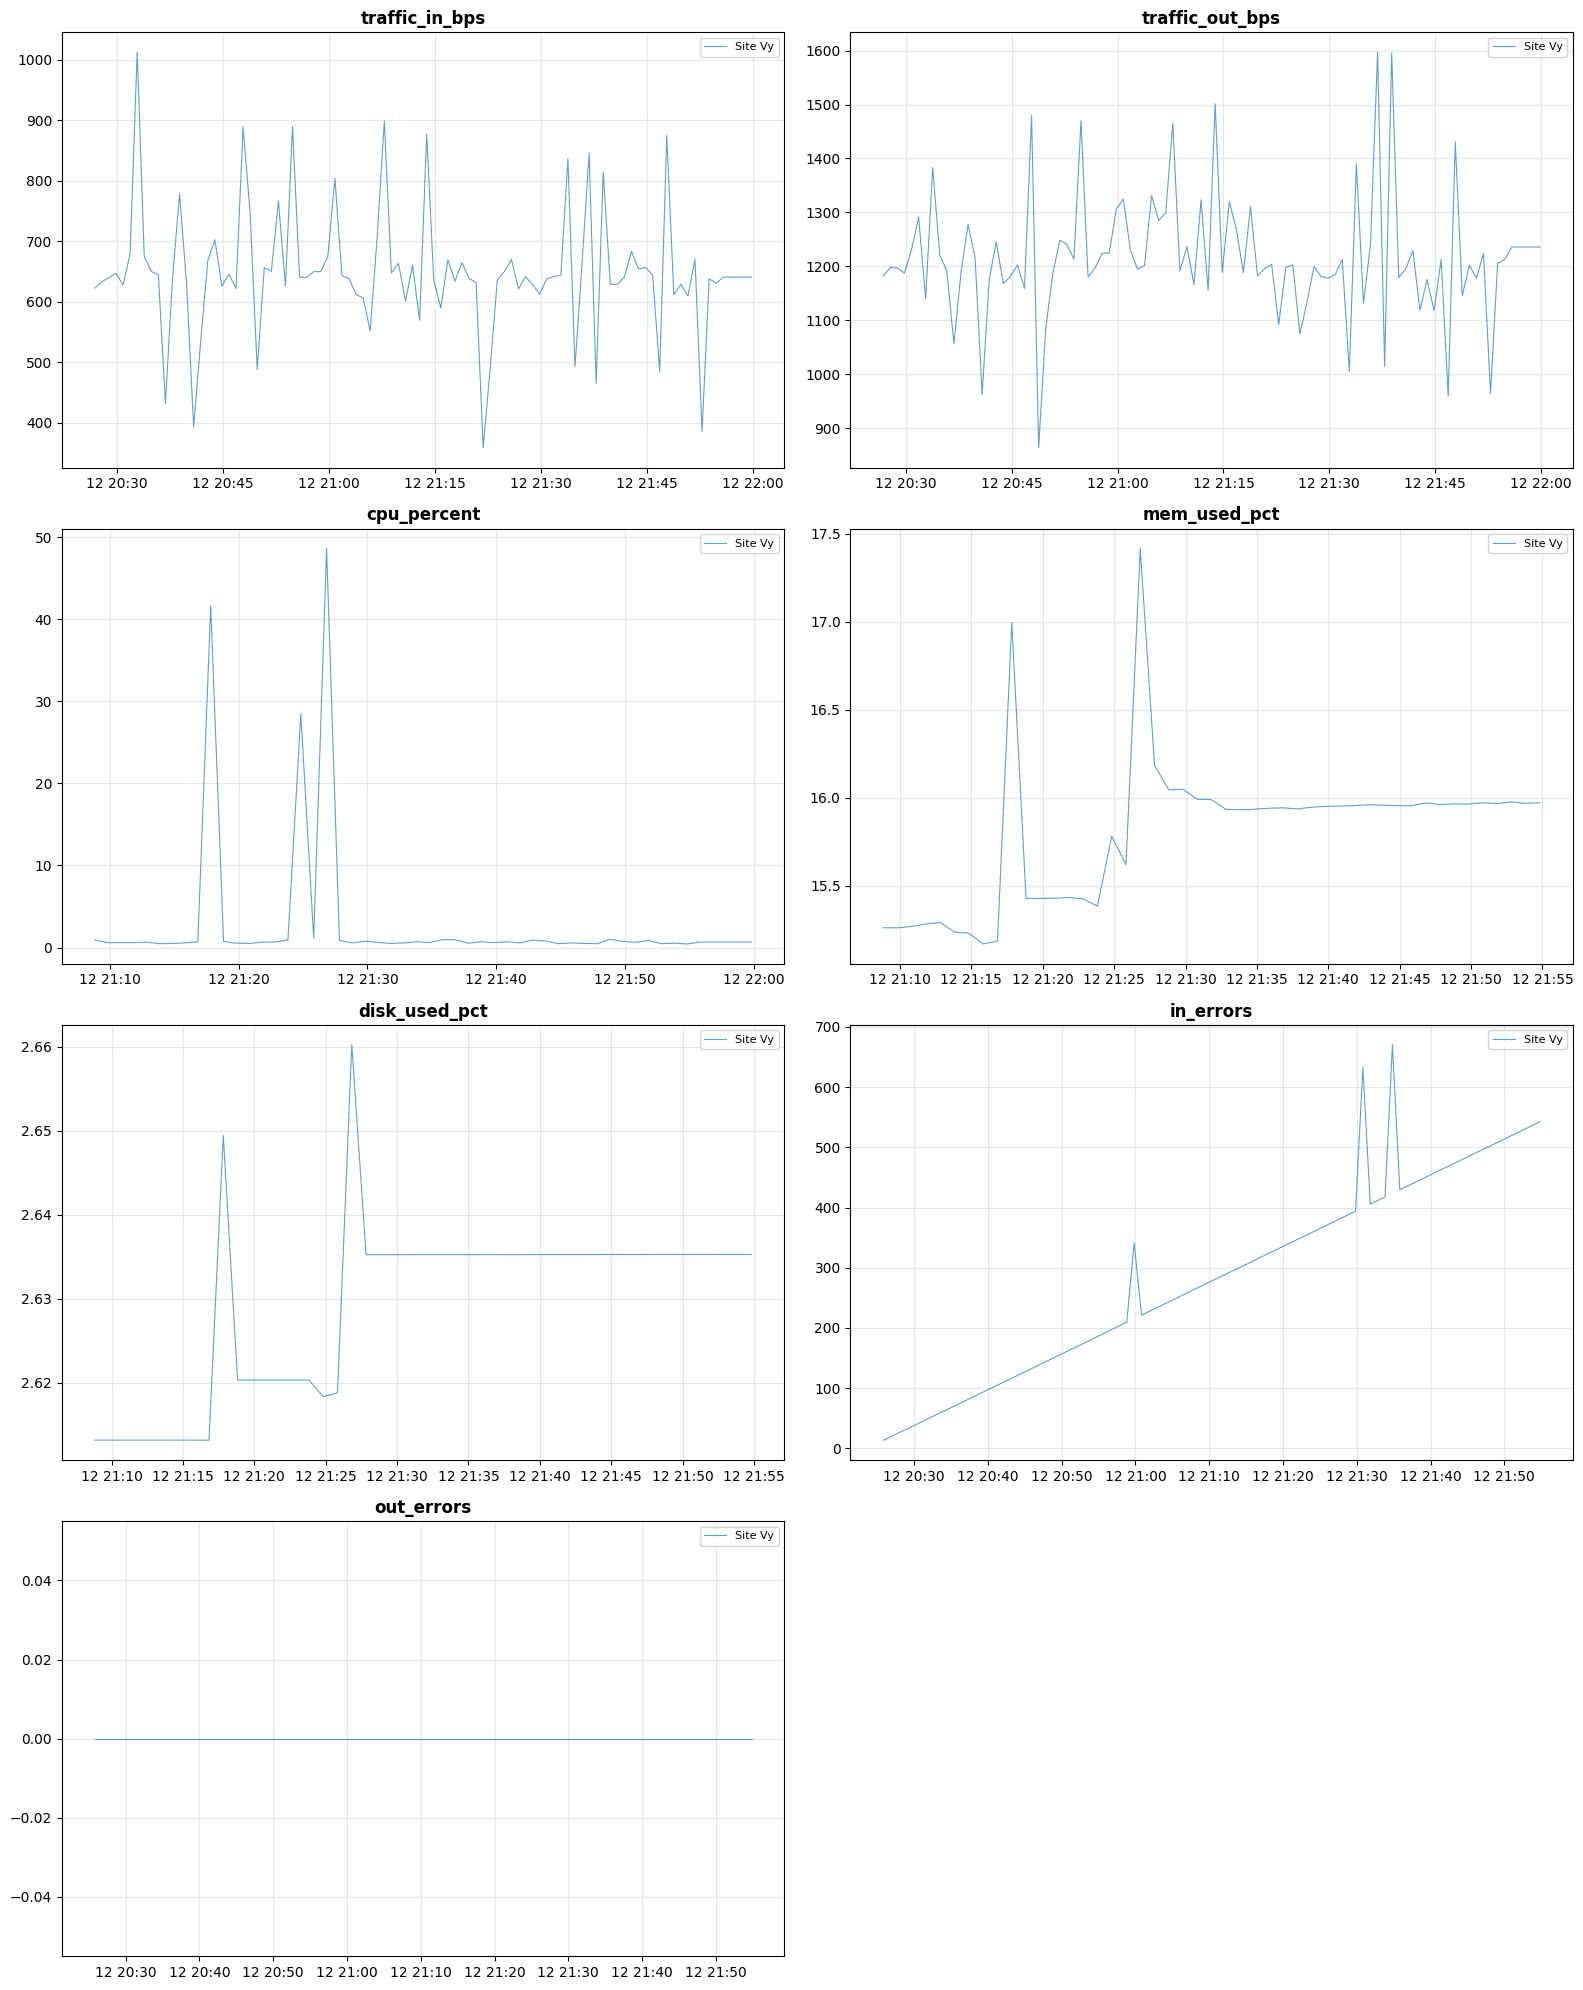

✅ Đã lưu biểu đồ


In [4]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
metrics_to_plot = ['traffic_in_bps','traffic_out_bps','cpu_percent',
                   'mem_used_pct','disk_used_pct','in_errors','out_errors']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx//2][idx%2]
    sub = df[df['metric'] == metric]

    for site in ['Vinh','Vuong','Vy']:
        site_data = sub[sub['site'] == site]
        if len(site_data) == 0: continue
        # Lấy giá trị tổng hợp (mean) theo thời gian
        ts = site_data.groupby('timestamp')['value'].mean()
        ax.plot(ts.index, ts.values, label=f'Site {site}',
                alpha=0.7, linewidth=0.8)

    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Ẩn subplot dư
axes[3][1].set_visible(False)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/network-monitor/data/metrics_overview.png', dpi=120)
plt.show()
print(" Đã lưu biểu đồ")

Train Isolation Forest

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import joblib, os

# Cấu hình train
METRICS_TO_TRAIN = {
    'traffic_in_bps':  {'contamination': 0.03, 'min_samples': 100},
    'traffic_out_bps': {'contamination': 0.03, 'min_samples': 100},
    'cpu_percent':     {'contamination': 0.05, 'min_samples': 50},
    'mem_used_pct':    {'contamination': 0.03, 'min_samples': 50},
    'disk_used_pct':   {'contamination': 0.02, 'min_samples': 50},
    'in_errors':       {'contamination': 0.05, 'min_samples': 50},
    'out_errors':      {'contamination': 0.05, 'min_samples': 50},
}

models = {}

print("=== TRAINING ISOLATION FOREST ===\n")
for metric, cfg in METRICS_TO_TRAIN.items():
    sub = df[df['metric'] == metric][['value']].dropna()

    # Lọc outlier cực đoan trước khi train (giá trị âm, infinity)
    sub = sub[np.isfinite(sub['value']) & (sub['value'] >= 0)]

    if len(sub) < cfg['min_samples']:
        print(f"  {metric:25s} | Chỉ có {len(sub)} samples — BỎ QUA (cần ≥{cfg['min_samples']})")
        continue

    # Scale
    scaler = StandardScaler()
    X = scaler.fit_transform(sub)

    # Train
    model = IsolationForest(
        n_estimators=200,
        contamination=cfg['contamination'],
        max_samples='auto',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X)

    # Đánh giá
    preds = model.predict(X)
    n_anom = (preds == -1).sum()
    pct    = n_anom / len(preds) * 100

    models[metric] = {"model": model, "scaler": scaler}
    print(f" {metric:25s} | samples={len(sub):6,} | "
          f"contamination={cfg['contamination']} | "
          f"anomalies={n_anom:4d} ({pct:.1f}%)")

print(f"\n Trained {len(models)}/{len(METRICS_TO_TRAIN)} models")

=== TRAINING ISOLATION FOREST ===

 traffic_in_bps            | samples= 1,786 | contamination=0.03 | anomalies=  54 (3.0%)
 traffic_out_bps           | samples= 1,786 | contamination=0.03 | anomalies=  53 (3.0%)
 cpu_percent               | samples=   102 | contamination=0.05 | anomalies=   6 (5.9%)
 mem_used_pct              | samples=    92 | contamination=0.03 | anomalies=   3 (3.3%)
 disk_used_pct             | samples=    92 | contamination=0.02 | anomalies=   2 (2.2%)
 in_errors                 | samples= 1,689 | contamination=0.05 | anomalies=  85 (5.0%)
 out_errors                | samples= 1,689 | contamination=0.05 | anomalies=   0 (0.0%)

 Trained 7/7 models


Visualize anomalies

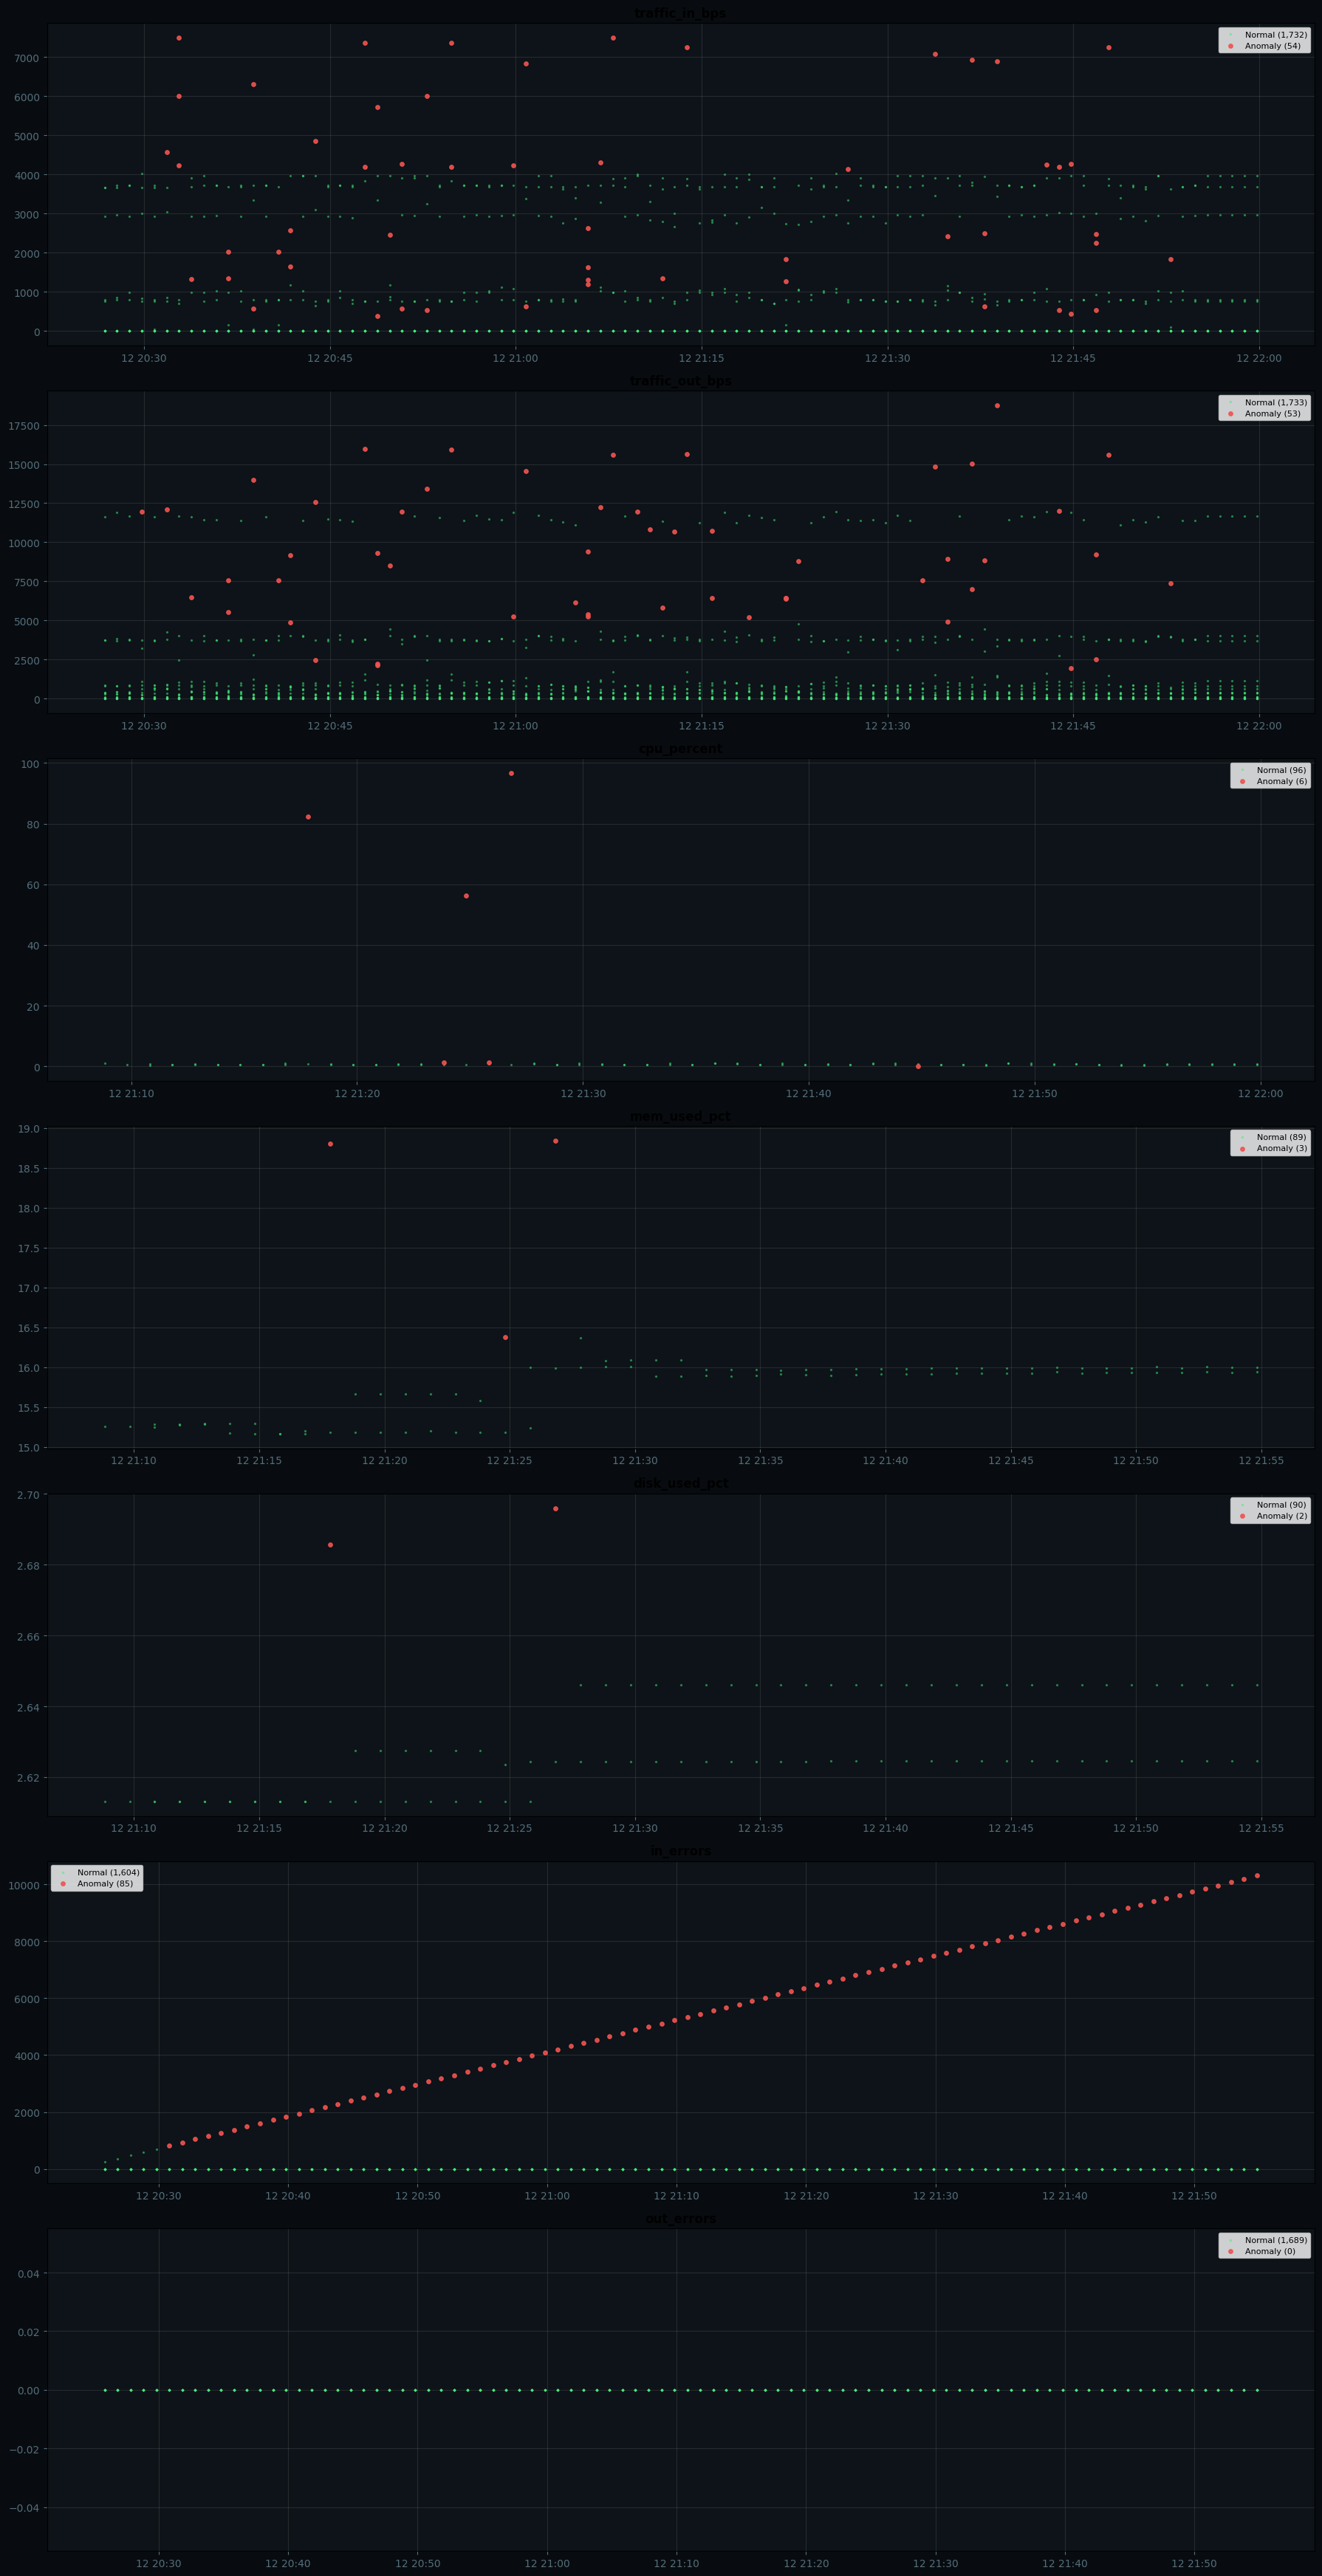

 Đã lưu biểu đồ anomaly


In [6]:
fig, axes = plt.subplots(len(models), 1, figsize=(18, 5*len(models)))
if len(models) == 1:
    axes = [axes]

for ax, (metric, m) in zip(axes, models.items()):
    sub = df[df['metric'] == metric].dropna(subset=['value'])
    sub = sub[np.isfinite(sub['value']) & (sub['value'] >= 0)].copy()

    X = m['scaler'].transform(sub[['value']])
    sub['anomaly'] = m['model'].predict(X)
    sub['score']   = m['model'].score_samples(X)

    normal    = sub[sub['anomaly'] ==  1]
    anomalous = sub[sub['anomaly'] == -1]

    ax.scatter(normal['timestamp'],    normal['value'],
               c='#43e97b', s=2, alpha=0.4, label=f'Normal ({len(normal):,})')
    ax.scatter(anomalous['timestamp'], anomalous['value'],
               c='#ef5350', s=15, alpha=0.9, zorder=5,
               label=f'Anomaly ({len(anomalous):,})')

    ax.set_title(f'{metric}', fontsize=12, fontweight='bold', pad=6)
    ax.set_facecolor('#0d1318')
    ax.tick_params(colors='#546e7a')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.15)

fig.patch.set_facecolor('#080c10')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/network-monitor/data/anomaly_detection.png', dpi=120)
plt.show()
print(" Đã lưu biểu đồ anomaly")

Validate model

In [7]:
print("=== VALIDATION ===\n")
print("Test với các giá trị biết trước:\n")

test_cases = [
    # (metric, value, expected)
    ('cpu_percent',    2.0,  'normal'),   # CPU thấp
    ('cpu_percent',    95.0, 'anomaly'),  # CPU rất cao
    ('mem_used_pct',   50.0, 'normal'),   # RAM bình thường
    ('mem_used_pct',   98.0, 'anomaly'),  # RAM gần đầy
    ('traffic_in_bps', 1e6,  'normal'),   # Traffic thấp
    ('in_errors',      0.0,  'normal'),   # Không có lỗi
    ('in_errors',      500.0,'anomaly'),  # Lỗi cao (errors/s)
]

for metric, value, expected in test_cases:
    if metric not in models:
        print(f"  SKIP {metric} (chưa có model)")
        continue
    m = models[metric]
    X = m['scaler'].transform([[value]])
    pred  = m['model'].predict(X)[0]
    score = m['model'].score_samples(X)[0]
    result = 'anomaly' if pred == -1 else 'normal'
    ok     = '✅' if result == expected else '❌'
    print(f"  {ok} {metric:25s} | value={value:10.1f} | "
          f"score={score:6.3f} | pred={result} (expected={expected})")

=== VALIDATION ===

Test với các giá trị biết trước:

  ❌ cpu_percent               | value=       2.0 | score=-0.678 | pred=anomaly (expected=normal)
  ✅ cpu_percent               | value=      95.0 | score=-0.827 | pred=anomaly (expected=anomaly)
  ❌ mem_used_pct              | value=      50.0 | score=-0.819 | pred=anomaly (expected=normal)
  ✅ mem_used_pct              | value=      98.0 | score=-0.819 | pred=anomaly (expected=anomaly)
  ❌ traffic_in_bps            | value= 1000000.0 | score=-0.827 | pred=anomaly (expected=normal)
  ✅ in_errors                 | value=       0.0 | score=-0.409 | pred=normal (expected=normal)
  ❌ in_errors                 | value=     500.0 | score=-0.633 | pred=normal (expected=anomaly)


 Export model

In [8]:
import os
save_dir = '/content/drive/MyDrive/network-monitor/models'
os.makedirs(save_dir, exist_ok=True)

print("=== EXPORT MODELS ===\n")
for metric, m in models.items():
    path = f"{save_dir}/isolation_forest_{metric}.pkl"
    joblib.dump({"model": m["model"], "scaler": m["scaler"]}, path)
    size = os.path.getsize(path) / 1024
    print(f"✅ isolation_forest_{metric}.pkl ({size:.0f} KB)")

print(f"\n🎉 Đã lưu {len(models)} models tại:")
print(f"   {save_dir}")
print("\nBước tiếp theo:")
print("  1. Download folder 'models' từ Google Drive")
print("  2. Copy vào ~/network-monitor-v2/models/")
print("  3. sudo systemctl restart network-monitor")

=== EXPORT MODELS ===

✅ isolation_forest_traffic_in_bps.pkl (1243 KB)
✅ isolation_forest_traffic_out_bps.pkl (1604 KB)
✅ isolation_forest_cpu_percent.pkl (566 KB)
✅ isolation_forest_mem_used_pct.pkl (1252 KB)
✅ isolation_forest_disk_used_pct.pkl (743 KB)
✅ isolation_forest_in_errors.pkl (576 KB)
✅ isolation_forest_out_errors.pkl (116 KB)

🎉 Đã lưu 7 models tại:
   /content/drive/MyDrive/network-monitor/models

Bước tiếp theo:
  1. Download folder 'models' từ Google Drive
  2. Copy vào ~/network-monitor-v2/models/
  3. sudo systemctl restart network-monitor
